# Dominant population-rate frequency across trials

This notebook expects the `.mat` files produced by Simulate_dynamics.py to be in `DATA_DIR`.  For each drive (`J0`–`J3`) and each trial, it concatenates the four saved 500-ms rate chunks, calculates `0.8 * rate_E + 0.2 * rate_I`, finds the largest spectral peak in the selected frequency range, and reports its mean and sample standard deviation across the five trials.

Mean field results saved in Theoretical_prediction_g3.159 was computed in folder theory/Fig3

In [1]:
from pathlib import Path
from scipy.io import loadmat, savemat
import numpy as np
import scipy.io as sio
from scipy import signal
import matplotlib.pyplot as plt

# Folder containing RATE_E_i*_J*_trial*.mat and RATE_I_i*_J*_trial*.mat files.
DATA_DIR = Path(".")

# Load stability results
g = 3.159
filename = f"Theoretical_prediction_{g:.3f}.mat" #This is computed in theory/
print(filename)
lc = loadmat(filename, squeeze_me=True)

# These are the values in List_syn_dist in the simulation script.
DRIVE_FACTORS =[0.8,0.833,0.866,0.9,0.933,0.966]

TRIALS = [1, 2, 3, 4, 5]
N_ITERATIONS = 4  # files i0, i1, i2, and i3 are concatenated within each trial

# Change this if the rate monitor was sampled at a different interval.
SAMPLE_INTERVAL_MS = 0.1

# The spectral maximum is searched only in this range; change it if needed.
FREQUENCY_BAND_HZ = (5.0, 60.0)

26caStability_g_fwdtest_3.159.mat


In [2]:
def rate_filename(population, iteration, drive_index, trial):
    return DATA_DIR / f"RATE_{population}_i{iteration}_J{drive_index}_trial{trial}.mat"


def load_rate(path):
    data = sio.loadmat(path)
    if "data" not in data:
        raise KeyError(f"{path.name} has no 'data' variable.")

    rate = np.asarray(data["data"], dtype=float).squeeze()
    if rate.ndim != 1:
        raise ValueError(f"Expected a one-dimensional rate in {path.name}; got shape {rate.shape}.")
    return rate


def load_population_rate(drive_index, trial):
    rate_e_chunks = []
    rate_i_chunks = []

    for iteration in range(N_ITERATIONS):
        e_path = rate_filename("E", iteration, drive_index, trial)
        i_path = rate_filename("I", iteration, drive_index, trial)

        missing = [str(path) for path in (e_path, i_path) if not path.exists()]
        if missing:
            raise FileNotFoundError("Missing file(s):\n" + "\n".join(missing))

        rate_e = load_rate(e_path)
        rate_i = load_rate(i_path)
        if rate_e.size != rate_i.size:
            raise ValueError(
                f"Different E/I lengths for J{drive_index}, trial {trial}, iteration {iteration}: "
                f"{rate_e.size} and {rate_i.size}."
            )

        rate_e_chunks.append(rate_e)
        rate_i_chunks.append(rate_i)

    rate_e = np.concatenate(rate_e_chunks)
    rate_i = np.concatenate(rate_i_chunks)
    return 0.8 * rate_e + 0.2 * rate_i


population_rates = {}
for drive_index, drive_factor in enumerate(DRIVE_FACTORS):
    for trial in TRIALS:
        population_rates[(drive_index, trial)] = load_population_rate(drive_index, trial)

    n_samples = population_rates[(drive_index, TRIALS[0])].size
    duration_s = n_samples * SAMPLE_INTERVAL_MS / 1000
    print(
        f"J{drive_index} (factor = {drive_factor}): {n_samples} samples per trial "
        f"({duration_s:.3f} s total)"
    )

J0 (factor = 0.8): 20000 samples per trial (2.000 s total)
J1 (factor = 0.833): 20000 samples per trial (2.000 s total)
J2 (factor = 0.866): 20000 samples per trial (2.000 s total)
J3 (factor = 0.9): 20000 samples per trial (2.000 s total)
J4 (factor = 0.933): 20000 samples per trial (2.000 s total)
J5 (factor = 0.966): 20000 samples per trial (2.000 s total)


In [3]:
def dominant_frequency(rate_hz, sample_interval_ms, frequency_band_hz):
    """Return the maximum periodogram frequency after removing the mean rate."""
    sampling_frequency_hz = 1000.0 / sample_interval_ms
    low_hz, high_hz = frequency_band_hz

    if not (0 < low_hz < high_hz < sampling_frequency_hz / 2):
        raise ValueError("FREQUENCY_BAND_HZ must lie between 0 and the Nyquist frequency.")

    frequencies, power = signal.periodogram(
        rate_hz - np.mean(rate_hz),
        fs=sampling_frequency_hz,
        window="hann",
        detrend=False,
        scaling="density",
    )

    in_band = (frequencies >= low_hz) & (frequencies <= high_hz)
    if not np.any(in_band):
        raise ValueError("No spectral frequencies fall in FREQUENCY_BAND_HZ.")

    band_frequencies = frequencies[in_band]
    band_power = power[in_band]
    return band_frequencies[np.argmax(band_power)]


frequencies_by_drive = {}
for drive_index, drive_factor in enumerate(DRIVE_FACTORS):
    peak_frequencies = np.array([
        dominant_frequency(
            population_rates[(drive_index, trial)],
            SAMPLE_INTERVAL_MS,
            FREQUENCY_BAND_HZ,
        )
        for trial in TRIALS
    ])
    frequencies_by_drive[drive_index] = peak_frequencies

    mean_frequency = np.mean(peak_frequencies)
    std_frequency = np.std(peak_frequencies, ddof=1)

    print(
        f"J{drive_index} (factor = {drive_factor}): "
        f"{mean_frequency:.2f} ± {std_frequency:.2f} Hz "
        f"(mean ± sample SD, n = {len(peak_frequencies)})"
    )
    print(f"  individual trials: {peak_frequencies}")

J0 (factor = 0.8): 12.00 ± 1.41 Hz (mean ± sample SD, n = 5)
  individual trials: [10.5 13.  13.5 12.5 10.5]
J1 (factor = 0.833): 13.70 ± 1.04 Hz (mean ± sample SD, n = 5)
  individual trials: [15.  13.  13.5 12.5 14.5]
J2 (factor = 0.866): 15.50 ± 0.61 Hz (mean ± sample SD, n = 5)
  individual trials: [15.5 15.5 15.  16.5 15. ]
J3 (factor = 0.9): 16.80 ± 0.76 Hz (mean ± sample SD, n = 5)
  individual trials: [18.  16.  16.5 16.5 17. ]
J4 (factor = 0.933): 17.70 ± 0.67 Hz (mean ± sample SD, n = 5)
  individual trials: [18.  18.  17.  18.5 17. ]
J5 (factor = 0.966): 18.90 ± 1.52 Hz (mean ± sample SD, n = 5)
  individual trials: [18.5 16.5 19.5 20.5 19.5]


In [4]:
list_varying_param = np.asarray(lc["list_varying_param"]).squeeze()
local_minima_all = np.atleast_1d(lc["local_minima_all"])

all_param_list = []
all_minima_list = []

for i, min_h in enumerate(local_minima_all):
    # MATLAB cell contents can arrive as object arrays
    min_h = np.asarray(min_h, dtype=float)

    # Skip parameter values for which no minima were found
    if min_h.size == 0:
        continue

    min_h = np.atleast_2d(min_h)

    nr_minima = min_h.shape[0]
    params_h = np.full(nr_minima, list_varying_param[i])

    all_param_list.append(params_h)
    all_minima_list.append(min_h)

all_param = np.concatenate(all_param_list)
all_minima = np.vstack(all_minima_list)

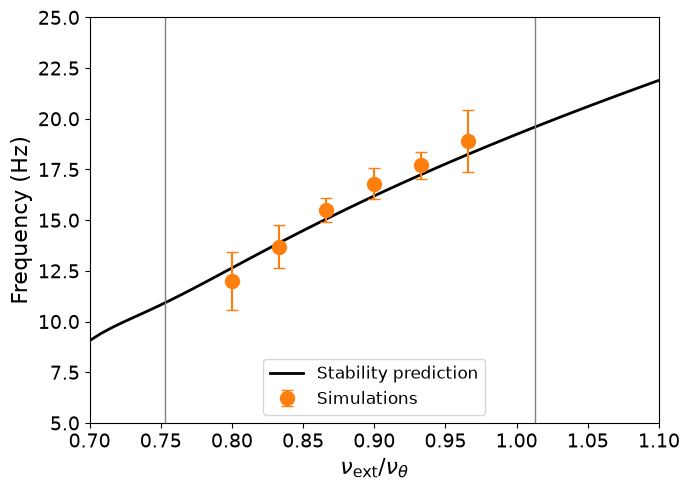

In [5]:
# Dominant-frequency summary from the preceding notebook cells
drive_values = np.asarray(DRIVE_FACTORS, dtype=float)
frequency_mean = np.array([
    np.mean(frequencies_by_drive[j])
    for j in range(len(DRIVE_FACTORS))
])
frequency_std = np.array([
    np.std(frequencies_by_drive[j], ddof=1)
    for j in range(len(DRIVE_FACTORS))
])

# One-panel frequency figure
fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(
    all_param,
    np.abs(all_minima[:, 1]),
    "k",
    linewidth=2,
    label="Stability prediction",
)

ax.errorbar(
    drive_values,
    frequency_mean,
    yerr=frequency_std,
    fmt="o",
    color="tab:orange",
    capsize=4,
    markersize=10,
    label="Simulations",
)

ax.set_xlim(0.7, 1.1)
ax.set_ylim(5, 25)

ax.axvline(0.75297574, color="gray",  linewidth=1)
ax.axvline(1.01318824, color="gray",  linewidth=1)

ax.set_xlabel(r"$\nu_{\mathrm{ext}}/\nu_{\theta}$", fontsize=16)
ax.set_ylabel("Frequency (Hz)", fontsize=16)
ax.tick_params(labelsize=14)
ax.legend(fontsize=12)

fig.tight_layout()
fig.savefig("dominant_frequency_mean_std.svg", format="svg", bbox_inches="tight")
plt.show()

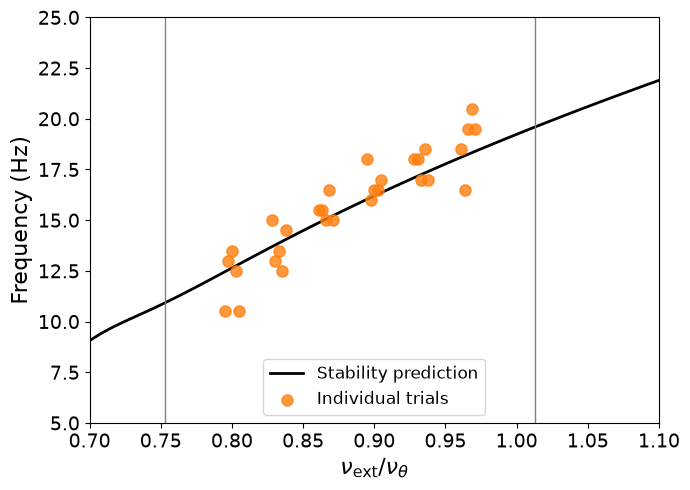

In [6]:
# Plot individual trial frequencies (no averaging)
fig, ax = plt.subplots(figsize=(7, 5))

# Stability prediction
ax.plot(
    all_param,
    np.abs(all_minima[:, 1]),
    "k",
    linewidth=2,
    label="Stability prediction",
)

# Individual simulation frequencies
for j, drive in enumerate(DRIVE_FACTORS):
    freqs = np.asarray(frequencies_by_drive[j])

    # Small horizontal offsets to distinguish overlapping trials
    offsets = np.linspace(-0.005, 0.005, len(freqs))

    ax.scatter(
        drive + offsets,
        freqs,
        color="tab:orange",
        s=65,
        alpha=0.8,
        label="Individual trials" if j == 0 else None,
        zorder=3,
    )

# Stability boundaries
ax.axvline(0.75297574, color="gray", linewidth=1)
ax.axvline(1.01318824, color="gray", linewidth=1)

# Include all drive values and measured frequencies
all_freqs = np.concatenate(list(frequencies_by_drive.values()))

ax.set_xlim(0.7, max(1.1, max(DRIVE_FACTORS) + 0.03))
ax.set_ylim(5, max(25, all_freqs.max() + 2))

ax.set_xlabel(r"$\nu_{\mathrm{ext}}/\nu_{\theta}$", fontsize=16)
ax.set_ylabel("Frequency (Hz)", fontsize=16)
ax.tick_params(labelsize=14)
ax.legend(fontsize=12)

fig.tight_layout()
plt.show()